# Week 01 – Earthquake Damage Prediction: Exploratory Data Analysis
**DS Lab 2026 – Phase 1**

Goals:
- Analyze distribution of individual features
- Analyze missing and default values, find uninformative columns
- Analyze relationships between features
- Analyze relationship of features to target (`damage_grade`)

## 0. Imports & Setup

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif

# Style settings
sns.set_theme(style='whitegrid', font_scale=1.2)
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['figure.dpi'] = 100

# Suppress warnings for cleaner output
import warnings
warnings.filterwarnings('ignore')

## 1. Load Data

In [5]:
# Adjust paths if needed – by default expects CSV files in the same folder as this notebook
X_train = pd.read_csv('train_values.csv').set_index('building_id')
y_train = pd.read_csv('train_labels.csv').set_index('building_id')
X_test  = pd.read_csv('test_values.csv').set_index('building_id')

# Merge features and target for joint analysis
df = X_train.copy()
df['damage_grade'] = y_train['damage_grade']

print(f'Training samples : {X_train.shape[0]:,}')
print(f'Test samples     : {X_test.shape[0]:,}')
print(f'Features         : {X_train.shape[1]}')

Training samples : 260,601
Test samples     : 86,868
Features         : 38


In [6]:
# Quick overview of the data
X_train.head()

,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,...,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other
building_id,,,,,,,,,,,,,,,,,,,,,
802906,6,487,12198,2,30,6,5,t,r,n,...,0,0,0,0,0,0,0,0,0,0
28830,8,900,2812,2,10,8,7,o,r,n,...,0,0,0,0,0,0,0,0,0,0
94947,21,363,8973,2,10,5,5,t,r,n,...,0,0,0,0,0,0,0,0,0,0
590882,22,418,10694,2,10,6,5,t,r,n,...,0,0,0,0,0,0,0,0,0,0
201944,11,131,1488,3,30,8,9,t,r,n,...,0,0,0,0,0,0,0,0,0,0


In [7]:
X_train.dtypes.value_counts()

int64    30
str       8
Name: count, dtype: int64

## 2. Target Variable: `damage_grade`

The target has three ordinal levels: 1 (low damage), 2 (medium damage), 3 (almost complete destruction).

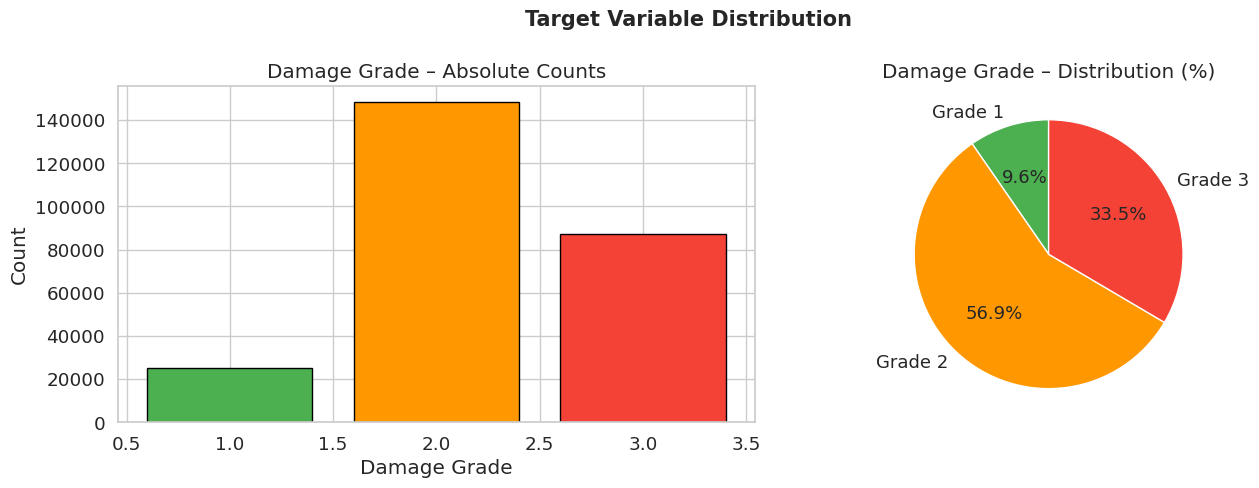

               count    pct
damage_grade               
1              25124   9.64
2             148259  56.89
3              87218  33.47


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Count plot
counts = y_train['damage_grade'].value_counts().sort_index()
axes[0].bar(counts.index, counts.values, color=['#4CAF50','#FF9800','#F44336'], edgecolor='black')
axes[0].set_xlabel('Damage Grade')
axes[0].set_ylabel('Count')
axes[0].set_title('Damage Grade – Absolute Counts')


# Percentage pie
axes[1].pie(counts.values, labels=[f'Grade {i}' for i in counts.index],
            autopct='%1.1f%%', colors=['#4CAF50','#FF9800','#F44336'],
            startangle=90, textprops={'fontsize': 13})
axes[1].set_title('Damage Grade – Distribution (%)')

plt.suptitle('Target Variable Distribution', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('target_distribution.pdf', bbox_inches='tight')
plt.show()

print(counts.to_frame('count').assign(pct=lambda x: (x['count']/x['count'].sum()*100).round(2)))

**Observation:** The dataset is imbalanced – grade 2 dominates. This will be important for modeling later.

## 3. Missing Values & Uninformative Columns

In [10]:
# Check for missing values
missing = X_train.isnull().sum()
print('Columns with missing values:')
print(missing[missing > 0] if missing.any() else 'None – no missing values found!')

Columns with missing values:
None – no missing values found!


In [11]:
# Check for constant or near-constant columns (potentially uninformative)
nunique = X_train.nunique().sort_values()
print('Columns with very few unique values (potential low-variance features):')
print(nunique[nunique <= 2])

Columns with very few unique values (potential low-variance features):
has_superstructure_mud_mortar_stone       2
has_superstructure_adobe_mud              2
has_secondary_use_institution             2
has_secondary_use_rental                  2
has_secondary_use_agriculture             2
has_secondary_use_hotel                   2
has_secondary_use                         2
has_superstructure_other                  2
has_superstructure_rc_engineered          2
has_superstructure_rc_non_engineered      2
has_superstructure_bamboo                 2
has_superstructure_timber                 2
has_superstructure_cement_mortar_brick    2
has_superstructure_mud_mortar_brick       2
has_superstructure_cement_mortar_stone    2
has_superstructure_stone_flag             2
has_secondary_use_gov_office              2
has_secondary_use_health_post             2
has_secondary_use_other                   2
has_secondary_use_use_police              2
has_secondary_use_industry                2
has_s

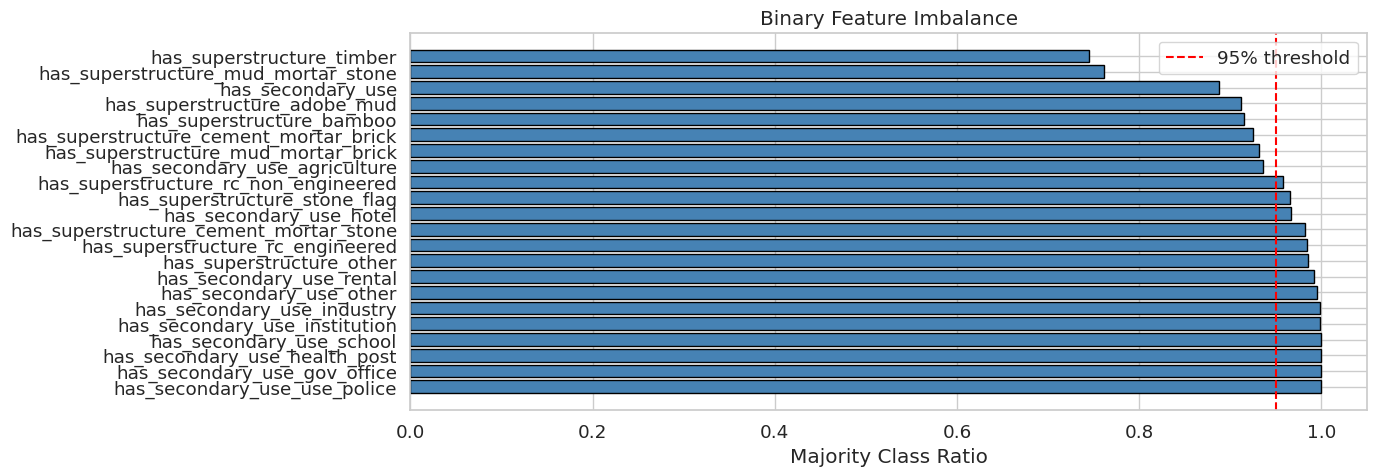

Binary features with >95% majority class (14 features):
                                        majority_ratio
has_secondary_use_use_police                  0.999912
has_secondary_use_gov_office                  0.999854
has_secondary_use_health_post                 0.999812
has_secondary_use_school                      0.999639
has_secondary_use_institution                 0.999060
has_secondary_use_industry                    0.998929
has_secondary_use_other                       0.994881
has_secondary_use_rental                      0.991899
has_superstructure_other                      0.985015
has_superstructure_rc_engineered              0.984141
has_superstructure_cement_mortar_stone        0.981765
has_secondary_use_hotel                       0.966374
has_superstructure_stone_flag                 0.965668
has_superstructure_rc_non_engineered          0.957410


In [ ]:
# Check value counts of binary (0/1) columns to spot very imbalanced ones
int_cols = X_train.select_dtypes(include='int64')
binary_cols = int_cols.columns[int_cols.nunique() == 2]

imbalance_ratio = {col: X_train[col].value_counts(normalize=True).max() for col in binary_cols}
imbalance_df = pd.DataFrame.from_dict(imbalance_ratio, orient='index', columns=['majority_ratio']).sort_values('majority_ratio', ascending=False)

fig, ax = plt.subplots(figsize=(14, 5))
bars = ax.barh(imbalance_df.index, imbalance_df['majority_ratio'], color='steelblue', edgecolor='black')
ax.axvline(0.95, color='red', linestyle='--', label='95% threshold')
ax.set_xlabel('Majority Class Ratio')
ax.set_title('Binary Feature Imbalance')
ax.legend()
plt.tight_layout()
plt.savefig('binary_imbalance.pdf', bbox_inches='tight')
plt.show()

highly_imbalanced = imbalance_df[imbalance_df['majority_ratio'] > 0.95]
print(f'Binary features with >95% majority class ({len(highly_imbalanced)} features):')
print(highly_imbalanced)

## 4. Numerical Feature Distributions

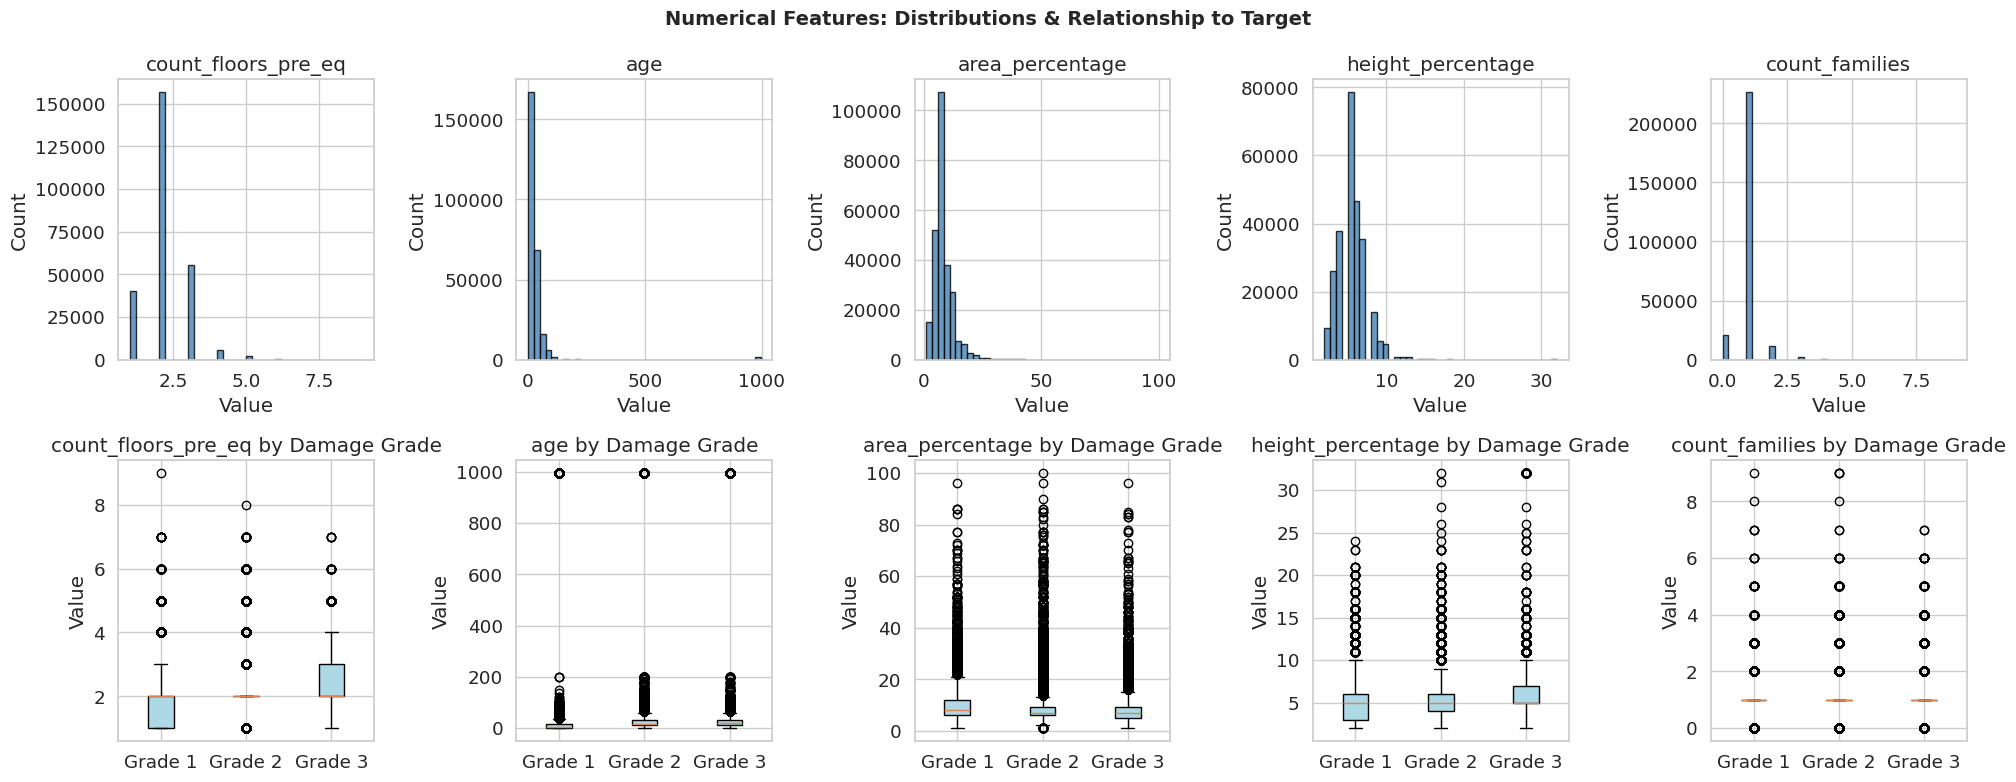

In [13]:
num_cols = ['count_floors_pre_eq', 'age', 'area_percentage', 'height_percentage', 'count_families']

fig, axes = plt.subplots(2, len(num_cols), figsize=(20, 8))

for i, col in enumerate(num_cols):
    # Histogram
    axes[0, i].hist(X_train[col], bins=40, color='steelblue', edgecolor='black', alpha=0.8)
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel('Value')
    axes[0, i].set_ylabel('Count')
    
    # Boxplot grouped by damage_grade
    data_by_grade = [df[df['damage_grade'] == g][col].values for g in [1, 2, 3]]
    axes[1, i].boxplot(data_by_grade, labels=['Grade 1', 'Grade 2', 'Grade 3'],
                       patch_artist=True,
                       boxprops=dict(facecolor='lightblue'))
    axes[1, i].set_title(f'{col} by Damage Grade')
    axes[1, i].set_ylabel('Value')

plt.suptitle('Numerical Features: Distributions & Relationship to Target', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('numerical_features.pdf', bbox_inches='tight')
plt.show()

In [14]:
# Summary statistics for numerical columns
X_train[num_cols].describe().round(2)

,count_floors_pre_eq,age,area_percentage,height_percentage,count_families
count,260601.00,260601.00,260601.00,260601.00,260601.00
mean,2.13,26.54,8.02,5.43,0.98
std,0.73,73.57,4.39,1.92,0.42
min,1.00,0.00,1.00,2.00,0.00
25%,2.00,10.00,5.00,4.00,1.00
50%,2.00,15.00,7.00,5.00,1.00
75%,2.00,30.00,9.00,6.00,1.00
max,9.00,995.00,100.00,32.00,9.00


**Observations to note:** Look for outliers (e.g., extreme `age` values), skewed distributions, and whether the distributions differ across damage grades.

## 5. Categorical Feature Distributions

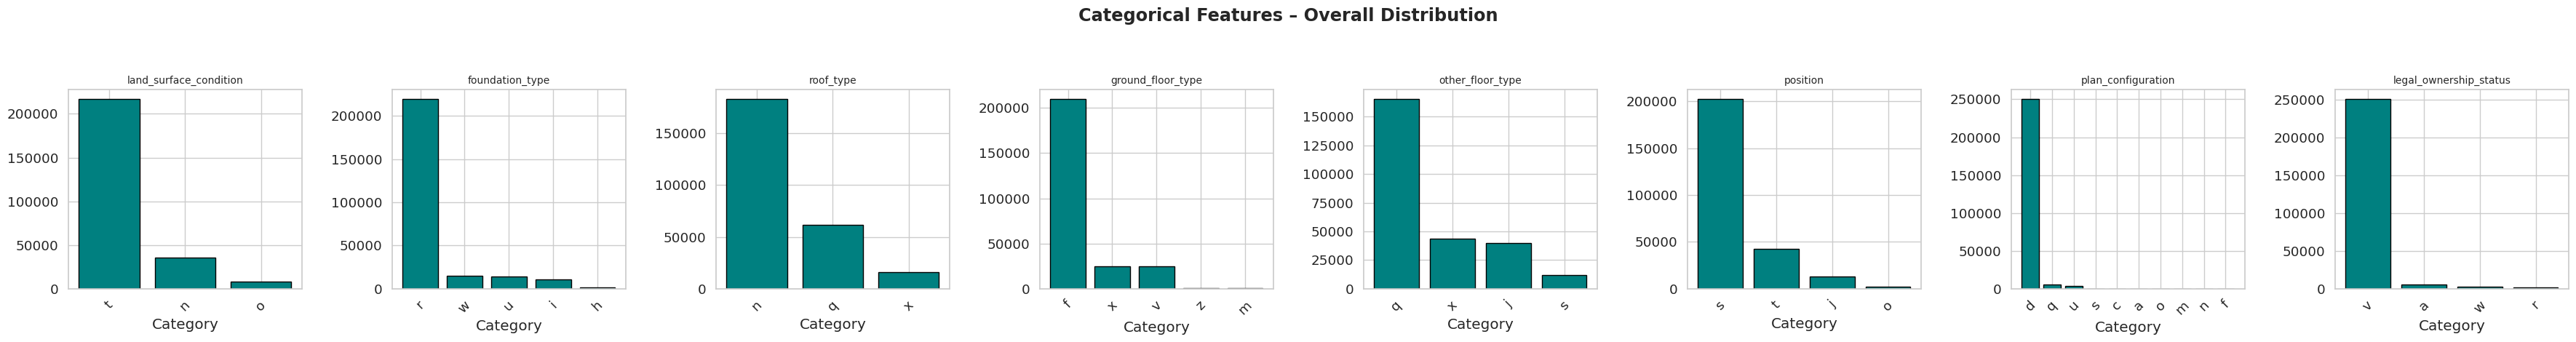

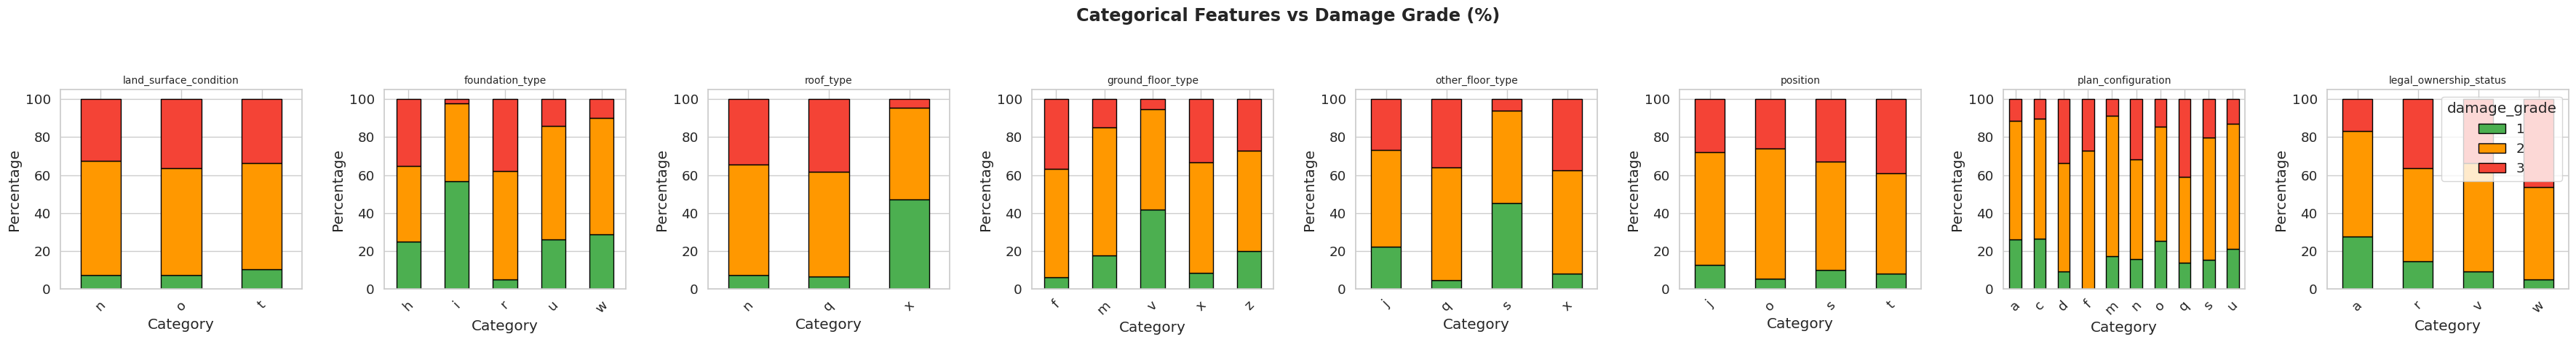

In [16]:
cat_cols = X_train.select_dtypes(include='object').columns.tolist()

# --- Plot 1: Verteilungen ---
fig, axes = plt.subplots(1, len(cat_cols), figsize=(36, 5))
for i, col in enumerate(cat_cols):
    vc = X_train[col].value_counts()
    axes[i].bar(vc.index, vc.values, color='teal', edgecolor='black')
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel('Category')
    axes[i].tick_params(axis='x', rotation=45)

plt.suptitle('Categorical Features – Overall Distribution', fontweight='bold')
plt.tight_layout(pad=2.0)
plt.savefig('categorical_distribution.pdf', bbox_inches='tight')
plt.show()

# --- Plot 2: vs Damage Grade ---
fig, axes = plt.subplots(1, len(cat_cols), figsize=(36, 5))
for i, col in enumerate(cat_cols):
    ct = pd.crosstab(df[col], df['damage_grade'], normalize='index') * 100
    ct.plot(kind='bar', stacked=True, ax=axes[i],
            color=['#4CAF50','#FF9800','#F44336'], edgecolor='black',
            legend=(i == len(cat_cols)-1))
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel('Category')
    axes[i].set_ylabel('Percentage')
    axes[i].tick_params(axis='x', rotation=45)

plt.suptitle('Categorical Features vs Damage Grade (%)', fontweight='bold')
plt.tight_layout(pad=2.0)
plt.savefig('categorical_vs_grade.pdf', bbox_inches='tight')
plt.show()

## 6. Geographic Features (geo_level IDs)

In [17]:
# How many unique geographic regions per level?
for col in ['geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id']:
    print(f'{col}: {X_train[col].nunique()} unique values')

geo_level_1_id: 31 unique values
geo_level_2_id: 1414 unique values
geo_level_3_id: 11595 unique values


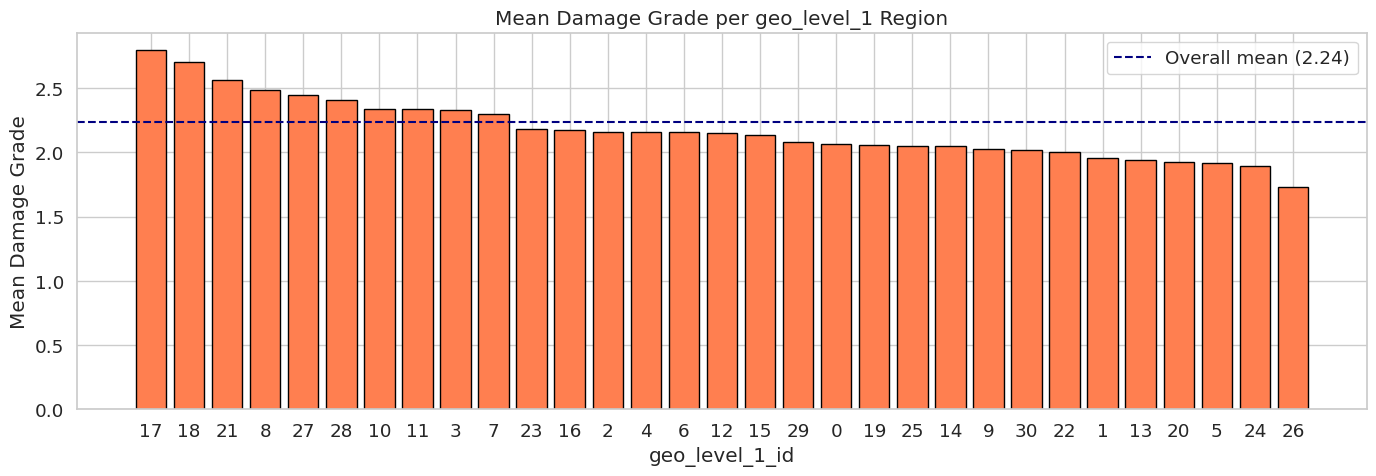


Regions with highest average damage:
geo_level_1_id
17    2.794480
18    2.708373
21    2.563369
8     2.485273
27    2.446457
Name: damage_grade, dtype: float64

Regions with lowest average damage:
geo_level_1_id
13    1.937656
20    1.926464
5     1.919703
24    1.894656
26    1.730887
Name: damage_grade, dtype: float64


In [18]:
# Mean damage grade per geo_level_1 region
geo1_damage = df.groupby('geo_level_1_id')['damage_grade'].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(14, 5))
bars = ax.bar(geo1_damage.index.astype(str), geo1_damage.values, color='coral', edgecolor='black')
ax.axhline(df['damage_grade'].mean(), color='navy', linestyle='--', label=f'Overall mean ({df["damage_grade"].mean():.2f})')
ax.set_xlabel('geo_level_1_id')
ax.set_ylabel('Mean Damage Grade')
ax.set_title('Mean Damage Grade per geo_level_1 Region')
ax.legend()
plt.tight_layout()
plt.savefig('geo_damage.pdf', bbox_inches='tight')
plt.show()

print('\nRegions with highest average damage:')
print(geo1_damage.head(5))
print('\nRegions with lowest average damage:')
print(geo1_damage.tail(5))

## 7. Superstructure Material Analysis

The dataset has many binary `has_superstructure_*` columns indicating which materials were used.

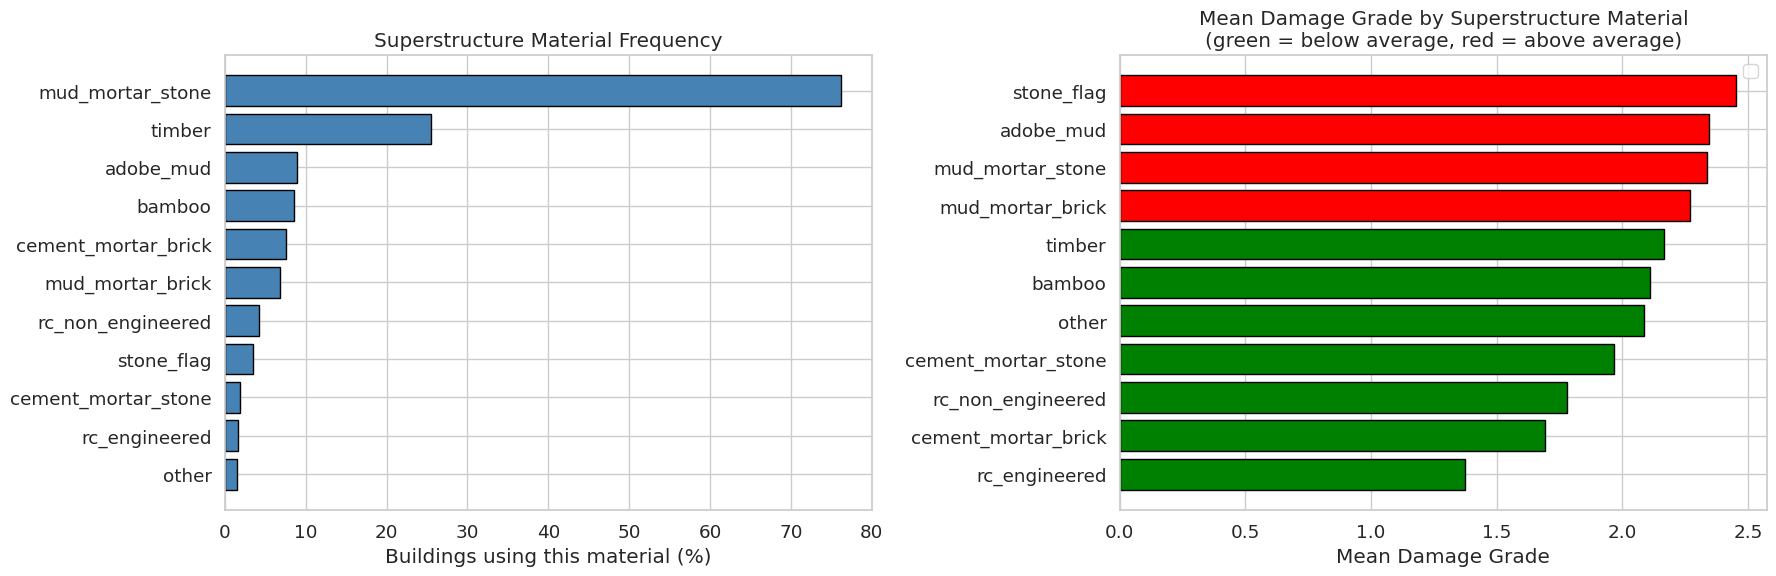

In [ ]:
superstructure_cols = [c for c in X_train.columns if c.startswith('has_superstructure')]

# How common is each material?
material_freq = X_train[superstructure_cols].mean().sort_values(ascending=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Frequency
axes[0].barh(material_freq.index.str.replace('has_superstructure_', ''),
             material_freq.values, color='steelblue', edgecolor='black')
axes[0].set_xlabel('Buildings using this material (%)')
axes[0].set_title('Superstructure Material Frequency')

# Mean damage grade per material
mean_damage = {col: df[df[col] == 1]['damage_grade'].mean() for col in superstructure_cols}
mean_damage_s = pd.Series(mean_damage).sort_values()
colors = ['green' if v < df['damage_grade'].mean() else 'red' for v in mean_damage_s.values]
axes[1].barh(mean_damage_s.index.str.replace('has_superstructure_', ''),
             mean_damage_s.values, color=colors, edgecolor='black')
axes[1].set_xlabel('Mean Damage Grade')
axes[1].set_title('Mean Damage Grade by Superstructure Material\n(green = below average, red = above average)')
axes[1].legend()

plt.tight_layout()
plt.savefig('superstructure_analysis.pdf', bbox_inches='tight')
plt.show()

## 8. Correlation Analysis (Numerical Features)

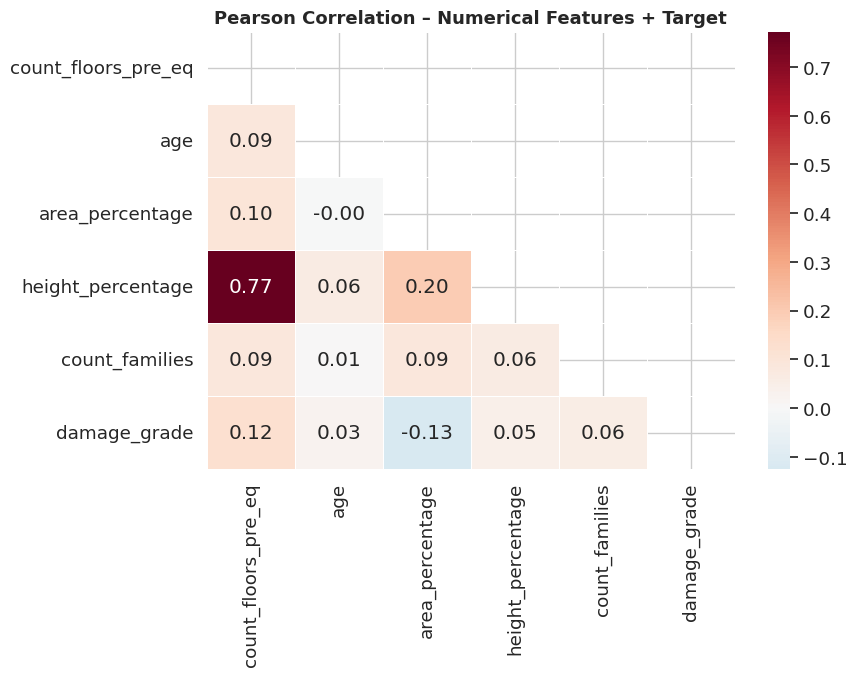


Correlation with damage_grade:
area_percentage       -0.125221
count_floors_pre_eq    0.122308
count_families         0.056151
height_percentage      0.048130
age                    0.029273
Name: damage_grade, dtype: float64


In [21]:
# Correlation matrix of numeric features + target
numeric_df = df[num_cols + ['damage_grade']]
corr_matrix = numeric_df.corr()

fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, mask=mask, ax=ax, linewidths=0.5)
ax.set_title('Pearson Correlation – Numerical Features + Target', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('correlation_matrix.pdf', bbox_inches='tight')
plt.show()

print('\nCorrelation with damage_grade:')
print(corr_matrix['damage_grade'].drop('damage_grade').sort_values(key=abs, ascending=False))

## 9. Mutual Information (All Features vs. Target)

Mutual information captures non-linear relationships and works for both numerical and encoded categorical features.

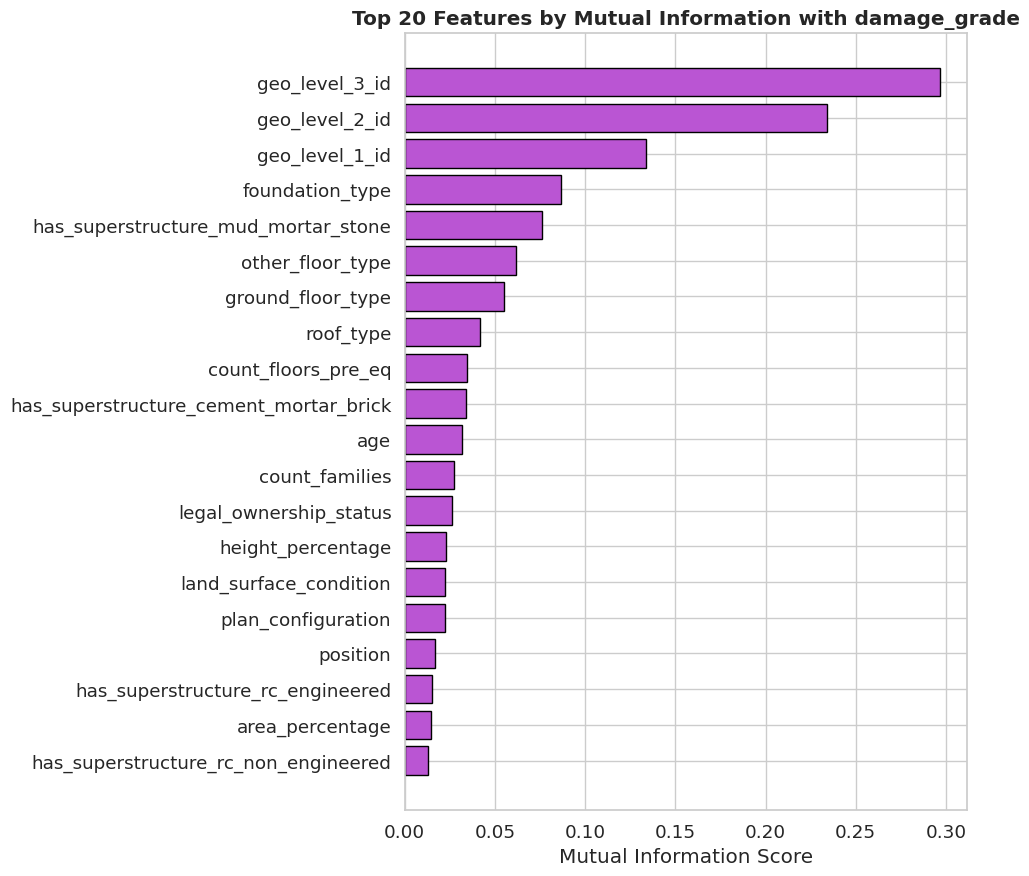


Top 10 most informative features:
geo_level_3_id                            0.2967
geo_level_2_id                            0.2341
geo_level_1_id                            0.1336
foundation_type                           0.0864
has_superstructure_mud_mortar_stone       0.0761
other_floor_type                          0.0617
ground_floor_type                         0.0550
roof_type                                 0.0417
count_floors_pre_eq                       0.0343
has_superstructure_cement_mortar_brick    0.0341
dtype: float64

Bottom 10 least informative features:
has_secondary_use_gov_office     0.0000
has_secondary_use_use_police     0.0000
has_secondary_use_school         0.0000
has_secondary_use_institution    0.0001
has_superstructure_other         0.0002
has_secondary_use_health_post    0.0007
has_secondary_use_other          0.0010
has_superstructure_bamboo        0.0011
has_secondary_use_industry       0.0013
has_superstructure_stone_flag    0.0022
dtype: float64


In [22]:
# Encode categorical columns with label encoding for MI computation
X_encoded = X_train.copy()
for col in X_encoded.select_dtypes(include='object').columns:
    X_encoded[col] = X_encoded[col].astype('category').cat.codes

# Compute mutual information
mi_scores = mutual_info_classif(X_encoded, y_train['damage_grade'], random_state=42)
mi_series = pd.Series(mi_scores, index=X_encoded.columns).sort_values(ascending=True)

# Plot top 20 features
fig, ax = plt.subplots(figsize=(10, 9))
top20 = mi_series.tail(20)
ax.barh(top20.index, top20.values, color='mediumorchid', edgecolor='black')
ax.set_xlabel('Mutual Information Score')
ax.set_title('Top 20 Features by Mutual Information with damage_grade', fontweight='bold')
plt.tight_layout()
plt.savefig('mutual_information.pdf', bbox_inches='tight')
plt.show()

print('\nTop 10 most informative features:')
print(mi_series.tail(10).iloc[::-1].round(4))
print('\nBottom 10 least informative features:')
print(mi_series.head(10).round(4))

## 10. Feature Redundancy Check

Check if any features are highly correlated with each other (potential redundancy).

In [23]:
# Full correlation matrix of all numerical + encoded features
corr_full = X_encoded.corr().abs()

# Find pairs with correlation > 0.7 (excluding self-correlation)
upper_tri = corr_full.where(np.triu(np.ones(corr_full.shape), k=1).astype(bool))
high_corr_pairs = [
    (col, row, upper_tri.loc[row, col])
    for col in upper_tri.columns
    for row in upper_tri.index
    if pd.notna(upper_tri.loc[row, col]) and upper_tri.loc[row, col] > 0.7
]

print(f'Feature pairs with |correlation| > 0.7: {len(high_corr_pairs)}')
if high_corr_pairs:
    for f1, f2, c in sorted(high_corr_pairs, key=lambda x: -x[2]):
        print(f'  {f1} <-> {f2}: {c:.3f}')
else:
    print('  No highly correlated feature pairs found.')

Feature pairs with |correlation| > 0.7: 2
  height_percentage <-> count_floors_pre_eq: 0.773
  has_secondary_use_agriculture <-> has_secondary_use: 0.739


## 11. Age vs. Damage Grade

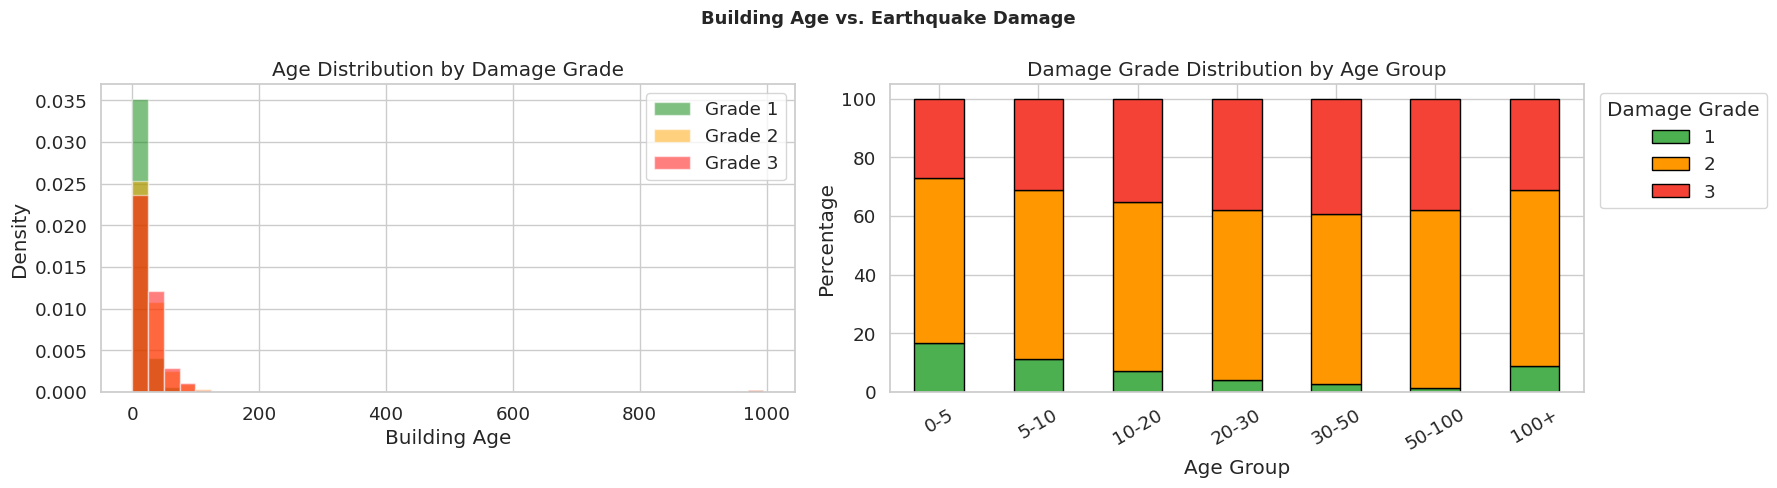

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))  

# Distribution of age per damage grade
for grade, color in zip([1, 2, 3], ['green', 'orange', 'red']):
    axes[0].hist(df[df['damage_grade'] == grade]['age'],
                 bins=40, alpha=0.5, color=color, label=f'Grade {grade}', density=True)
axes[0].set_xlabel('Building Age')
axes[0].set_ylabel('Density')
axes[0].set_title('Age Distribution by Damage Grade')
axes[0].legend()

# Age binned
df['age_bin'] = pd.cut(df['age'], bins=[0, 5, 10, 20, 30, 50, 100, 1000],
                       labels=['0-5','5-10','10-20','20-30','30-50','50-100','100+'])
ct = pd.crosstab(df['age_bin'], df['damage_grade'], normalize='index') * 100
ct.plot(kind='bar', stacked=True, ax=axes[1],
        color=['#4CAF50','#FF9800','#F44336'], edgecolor='black')
axes[1].set_xlabel('Age Group')
axes[1].set_ylabel('Percentage')
axes[1].set_title('Damage Grade Distribution by Age Group')
axes[1].tick_params(axis='x', rotation=30)


axes[1].legend(
    title='Damage Grade',
    bbox_to_anchor=(1.01, 1), 
    loc='upper left'           
)

plt.suptitle('Building Age vs. Earthquake Damage', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('age_analysis.pdf', bbox_inches='tight')  # bbox_inches='tight' wichtig!
plt.show()

## 12. Summary of Key Findings

In [31]:
print('='*60)
print('SUMMARY OF KEY FINDINGS')
print('='*60)
print()
print('Dataset:')
print(f'  - {X_train.shape[0]:,} training samples, {X_train.shape[1]} features')
print(f'  - {X_test.shape[0]:,} test samples')
print()
print('Target (damage_grade):')
for g, c in y_train['damage_grade'].value_counts().sort_index().items():
    pct = c / len(y_train) * 100
    print(f'  - Grade {g}: {c:,} ({pct:.1f}%)')
print()
print('Missing values:')
print(f'  - {X_train.isnull().sum().sum()} total missing values')
print()
print('Features:')
print(f'  - Categorical: {len(X_train.select_dtypes("object").columns)} columns')
print(f'  - Numerical  : {len(X_train.select_dtypes("number").columns)} columns')
print()
print('Top 5 most informative features (by Mutual Information):')
for feat, score in mi_series.tail(5).iloc[::-1].items():
    print(f'  - {feat}: {score:.4f}')
print()
print('Highly imbalanced binary features (>95% one class):')
for feat, ratio in highly_imbalanced.iterrows():
    print(f'  - {feat}: {ratio["majority_ratio"]*100:.1f}% majority')

SUMMARY OF KEY FINDINGS

Dataset:
  - 260,601 training samples, 38 features
  - 86,868 test samples

Target (damage_grade):
  - Grade 1: 25,124 (9.6%)
  - Grade 2: 148,259 (56.9%)
  - Grade 3: 87,218 (33.5%)

Missing values:
  - 0 total missing values

Features:
  - Categorical: 8 columns
  - Numerical  : 30 columns

Top 5 most informative features (by Mutual Information):
  - geo_level_3_id: 0.2967
  - geo_level_2_id: 0.2341
  - geo_level_1_id: 0.1336
  - foundation_type: 0.0864
  - has_superstructure_mud_mortar_stone: 0.0761

Highly imbalanced binary features (>95% one class):
  - has_secondary_use_use_police: 100.0% majority
  - has_secondary_use_gov_office: 100.0% majority
  - has_secondary_use_health_post: 100.0% majority
  - has_secondary_use_school: 100.0% majority
  - has_secondary_use_institution: 99.9% majority
  - has_secondary_use_industry: 99.9% majority
  - has_secondary_use_other: 99.5% majority
  - has_secondary_use_rental: 99.2% majority
  - has_superstructure_other: 9